# Setting up libs and importing data

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import json

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from scipy.cluster.hierarchy import linkage, dendrogram

# Set plot styling
sns.set_theme(style="white")

# =====================================================================
# 1. Load World Bank Data
# =====================================================================

# Load WDI data from main.csv
data = pd.read_csv("WDICSV.csv")

print("Data shape:", data.shape)
data.head()

Data shape: (398468, 70)


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,18.471500,18.822373,19.302882,19.770426,20.120927,20.440680,20.817895,21.161010,21.532841,NaN
1,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,7.682625,7.953281,8.528101,8.878267,9.050266,9.111884,9.285654,9.403676,9.687390,NaN
2,Africa Eastern and Southern,AFE,Access to clean fuels and technologies for coo...,EG.CFT.ACCS.UR.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,39.163151,39.206303,39.406216,39.569413,39.958115,40.025590,40.203585,40.728295,41.118943,NaN
3,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.859598,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN
4,Africa Eastern and Southern,AFE,"Access to electricity, rural (% of rural popul...",EG.ELC.ACCS.RU.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,24.584906,25.375037,26.941984,28.983183,30.909991,32.709837,33.998179,35.240236,36.080572,NaN


# Keeping given 11 indicators and year as 2022

In [7]:
YEAR = "2022"

indicators = {
    "GDP_PC": "NY.GDP.PCAP.CD",
    "GDP_Growth": "NY.GDP.MKTP.KD.ZG",
    "Inflation": "FP.CPI.TOTL.ZG",
    "Unemployment": "SL.UEM.TOTL.ZS",
    "Trade": "NE.TRD.GNFS.ZS",
    "Capital_Formation": "NE.GDI.TOTL.ZS",
    "Life_Expectancy": "SP.DYN.LE00.IN",
    "Urban_Population": "SP.URB.TOTL.IN.ZS",
    "Internet_Users": "IT.NET.USER.ZS",
    "Electricity_Access": "EG.ELC.ACCS.ZS",
    "Secondary_Enrollment": "SE.SEC.ENRR"
}

features = list(indicators.keys())
indicator_codes = list(indicators.values())

data_selected = data[
    data["Indicator Code"].isin(indicator_codes)
].copy()

data_selected.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
3,Africa Eastern and Southern,AFE,Access to electricity (% of population),EG.ELC.ACCS.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,38.859598,40.223744,43.035073,44.390861,46.282371,48.127211,48.742043,50.667516,52.598171,NaN
514,Africa Eastern and Southern,AFE,GDP growth (annual %),NY.GDP.MKTP.KD.ZG,NaN,0.418605,7.937089,5.624317,4.650349,5.138153,...,2.292501,2.678863,2.706207,1.935593,-2.930764,4.452643,3.668029,1.941382,2.787931,3.743016
518,Africa Eastern and Southern,AFE,GDP per capita (current US$),NY.GDP.PCAP.CD,186.089515,186.909365,197.367876,225.400456,208.963066,226.836513,...,1335.743165,1529.923080,1553.617944,1508.031525,1351.503167,1560.894626,1675.902524,1571.132704,1628.227289,1722.385620
565,Africa Eastern and Southern,AFE,Gross capital formation (% of GDP),NE.GDI.TOTL.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,22.020441,22.000905,21.780866,21.771203,19.511949,19.643056,20.460209,19.843989,18.509686,18.192575
662,Africa Eastern and Southern,AFE,Individuals using the Internet (% of population),IT.NET.USER.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,16.300000,17.300000,19.600000,21.600000,23.500000,25.000000,26.800000,27.800000,28.800000,30.400000


# Reshaping data to make each row = 1 country

In [9]:
data_wide = data_selected.pivot(
    index=["Country Name", "Country Code"],
    columns="Indicator Code",
    values=YEAR
)

data_wide = data_wide.reset_index()

data_wide.head()

Indicator Code,Country Name,Country Code,EG.ELC.ACCS.ZS,FP.CPI.TOTL.ZG,IT.NET.USER.ZS,NE.GDI.TOTL.ZS,NE.TRD.GNFS.ZS,NY.GDP.MKTP.KD.ZG,NY.GDP.PCAP.CD,SE.SEC.ENRR,SL.UEM.TOTL.ZS,SP.DYN.LE00.IN,SP.URB.TOTL.IN.ZS
0,Afghanistan,AFG,85.300000,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100000,65.617000,25.393925
1,Africa Eastern and Southern,AFE,48.742043,10.883478,26.800000,20.460209,57.117376,3.668029,1675.902524,45.281620,7.869470,64.487152,37.360578
2,Africa Western and Central,AFW,55.585594,7.949251,37.500000,NaN,NaN,4.477108,2143.072094,45.637299,3.596538,57.978995,51.700103
3,Albania,ALB,100.000000,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785000,78.769000,57.864348
4,Algeria,DZA,100.000000,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382000,76.129000,74.179586


In [11]:
# Making indicator-code columns to readable names:
indicator_names = {
    code: name for name, code in indicators.items()
}

data_wide = data_wide.rename(columns=indicator_names)

data_wide.head()

Indicator Code,Country Name,Country Code,Electricity_Access,Inflation,Internet_Users,Capital_Formation,Trade,GDP_Growth,GDP_PC,Secondary_Enrollment,Unemployment,Life_Expectancy,Urban_Population
0,Afghanistan,AFG,85.300000,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100000,65.617000,25.393925
1,Africa Eastern and Southern,AFE,48.742043,10.883478,26.800000,20.460209,57.117376,3.668029,1675.902524,45.281620,7.869470,64.487152,37.360578
2,Africa Western and Central,AFW,55.585594,7.949251,37.500000,NaN,NaN,4.477108,2143.072094,45.637299,3.596538,57.978995,51.700103
3,Albania,ALB,100.000000,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785000,78.769000,57.864348
4,Algeria,DZA,100.000000,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382000,76.129000,74.179586


# Removing the world bank aggregate entities before PCA or clustering
The data from the API (which is kept in api.json) contains the world bank metadata. 
In that file, aggregate entities have:region.value = "Aggregates" such as World, Africa, and Upper middle income as aggregates

In [15]:
with open("api.json", "r", encoding="utf-8") as f:
    api = json.load(f)

metadata = pd.DataFrame([
    {
        "Country Code": country["id"],
        "Region": country["region"]["value"].strip(),
        "LendingType": country["lendingType"]["value"].strip(),
        "IncomeGroup": country["incomeLevel"]["value"].strip()
    }
    for country in api[1]
])

metadata.head()

,Country Code,Region,LendingType,IncomeGroup
0,ABW,Latin America & Caribbean,Not classified,High income
1,AFE,Aggregates,Aggregates,Aggregates
2,AFG,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
3,AFR,Aggregates,Aggregates,Aggregates
4,AFW,Aggregates,Aggregates,Aggregates


In [72]:
# Keepig only actual countries/economies
metadata = metadata[
    metadata["Region"] != "Aggregates"
].copy()

# Remove any metadata columns already present in data_wide ( since Re running the cell gives merge error. I am dropping before merging
data_wide = data_wide.drop(
    columns=["Region", "LendingType", "IncomeGroup"],
    errors="ignore"
)

# Add the metadata
data_wide = data_wide.merge(
    metadata,
    on="Country Code",
    how="inner"
)

data_wide.head()


,Country Name,Country Code,Electricity_Access,Inflation,Internet_Users,Capital_Formation,Trade,GDP_Growth,GDP_PC,Secondary_Enrollment,...,IncomeGroup_x,Region_y,LendingType_y,IncomeGroup_y,KMeans_Cluster,Distance_to_Centroid,Hierarchical_Cluster,Region,LendingType,IncomeGroup
0,Afghanistan,AFG,85.3,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,...,Low income,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income,1,2.006322,1,"Middle East, North Africa, Afghanistan & Pakistan",IDA,Low income
1,Albania,ALB,100.0,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,...,Upper middle income,Europe & Central Asia,IBRD,Upper middle income,2,1.154216,1,Europe & Central Asia,IBRD,Upper middle income
2,Algeria,DZA,100.0,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,...,Upper middle income,"Middle East, North Africa, Afghanistan & Pakistan",IBRD,Upper middle income,2,2.010324,1,"Middle East, North Africa, Afghanistan & Pakistan",IBRD,Upper middle income
3,Andorra,AND,100.0,NaN,94.051697,NaN,NaN,9.564612,42414.059011,98.509872,...,High income,Europe & Central Asia,Not classified,High income,2,1.344773,2,Europe & Central Asia,Not classified,High income
4,Angola,AGO,48.5,21.355290,35.838001,14.506248,56.538072,3.557492,3598.536691,NaN,...,Lower middle income,Sub-Saharan Africa,IBRD,Lower middle income,1,2.224430,1,Sub-Saharan Africa,IBRD,Lower middle income


In [30]:
print("Number of countries/economies:", len(data_wide))
print(data_wide["Region"].value_counts())

Number of countries/economies: 217
Region
Europe & Central Asia                                58
Sub-Saharan Africa                                   48
Latin America & Caribbean                            42
East Asia & Pacific                                  37
Middle East, North Africa, Afghanistan & Pakistan    23
South Asia                                            6
North America                                         3
Name: count, dtype: int64


In [74]:
# Obtaining Region, LendingType, and held-out IncomeGroup
# validating 11 indicators are used
    
data_wide[
    [
        "Country Name",
        "Country Code",
        "Region",
        "LendingType",
        "IncomeGroup"
    ]
].head(10)

print("Number of WDI indicators:", len(features))
print(features)

Number of WDI indicators: 11
['GDP_PC', 'GDP_Growth', 'Inflation', 'Unemployment', 'Trade', 'Capital_Formation', 'Life_Expectancy', 'Urban_Population', 'Internet_Users', 'Electricity_Access', 'Secondary_Enrollment']


In [34]:
# Preprocessing data with PCA

In [36]:
# finding out missing data

missing_count = data_wide[features].isna().sum()

missing_percent = (
    data_wide[features].isna().mean() * 100
)

missing = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percent": missing_percent
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
Secondary_Enrollment,77,35.483871
Capital_Formation,42,19.354839
Inflation,38,17.511521
Internet_Users,35,16.129032
Trade,34,15.668203
Unemployment,31,14.285714
GDP_PC,8,3.686636
GDP_Growth,8,3.686636
Electricity_Access,2,0.921659
Life_Expectancy,0,0.000000


In [37]:
country_missing = data_wide[features].isna().mean(axis=1)

print("Countries with missing data:")
print((country_missing > 0).sum())

print("Countries with more than 50% missing:")
print((country_missing > 0.50).sum())

Countries with missing data:
107
Countries with more than 50% missing:
12


In [38]:
# Given the above information on the missing data, we can or the clustering, we can take an approach to remove countries with more than 50% missing indicators, 
# and median-impute the remaining missing values

In [76]:
#Making an assumption to keep 50% as a threshold for missing data
keep = country_missing <= 0.50
data_wide = data_wide[keep].copy()
X_data = data_wide[features].copy()

C:\Users\abhas\AppData\Local\Temp\ipykernel_17236\4195737107.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data_wide = data_wide[keep].copy()


In [40]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_data)

In [45]:
# clustering features
# every indicator has approximately mu=0 and sigma=1

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

In [46]:
# Examing correlations
correlation_matrix = pd.DataFrame(
    X_scaled,
    columns=features
).corr()

correlation_matrix

,GDP_PC,GDP_Growth,Inflation,Unemployment,Trade,Capital_Formation,Life_Expectancy,Urban_Population,Internet_Users,Electricity_Access,Secondary_Enrollment
GDP_PC,1.000000,0.055758,-0.145202,-0.177587,0.334798,-0.022883,0.574132,0.523665,0.496562,0.337417,0.354833
GDP_Growth,0.055758,1.000000,-0.114742,0.049904,-0.054194,0.148899,0.043897,-0.086286,0.010282,0.011449,0.020390
Inflation,-0.145202,-0.114742,1.000000,0.057104,-0.148246,-0.257351,-0.068708,-0.050295,-0.049025,-0.076822,-0.080460
Unemployment,-0.177587,0.049904,0.057104,1.000000,0.006556,-0.173125,-0.106338,0.047743,-0.006894,-0.015676,0.047926
Trade,0.334798,-0.054194,-0.148246,0.006556,1.000000,-0.052188,0.333263,0.295472,0.369576,0.236618,0.167756
Capital_Formation,-0.022883,0.148899,-0.257351,-0.173125,-0.052188,1.000000,0.080139,-0.102080,0.004958,0.069310,-0.035100
Life_Expectancy,0.574132,0.043897,-0.068708,-0.106338,0.333263,0.080139,1.000000,0.549563,0.756295,0.731457,0.326135
Urban_Population,0.523665,-0.086286,-0.050295,0.047743,0.295472,-0.102080,0.549563,1.000000,0.655168,0.494449,0.319975
Internet_Users,0.496562,0.010282,-0.049025,-0.006894,0.369576,0.004958,0.756295,0.655168,1.000000,0.843481,0.348749
Electricity_Access,0.337417,0.011449,-0.076822,-0.015676,0.236618,0.069310,0.731457,0.494449,0.843481,1.000000,0.224647


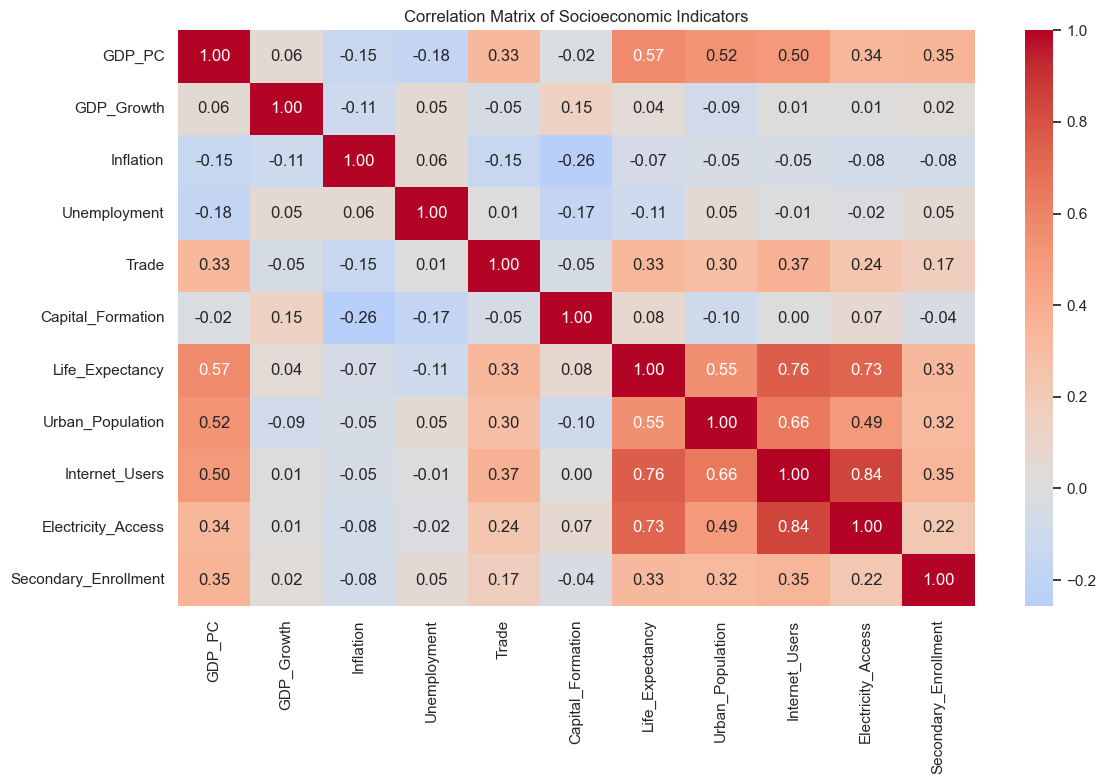

In [47]:
# Plotting it
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Socioeconomic Indicators")
plt.tight_layout()
plt.show()

In [48]:
# Applying PCA to the standardized data
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)
explained_variance = pca.explained_variance_ratio_
explained_variance

array([0.34624638, 0.12992591, 0.09841924, 0.0925161 , 0.08168059,
       0.07291787, 0.0596785 , 0.05072588, 0.03656978, 0.02099686,
       0.01032289])

In [49]:
# Calculating cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

cumulative_variance

array([0.34624638, 0.47617228, 0.57459153, 0.66710763, 0.74878822,
       0.82170609, 0.88138459, 0.93211047, 0.96868025, 0.98967711,
       1.        ])

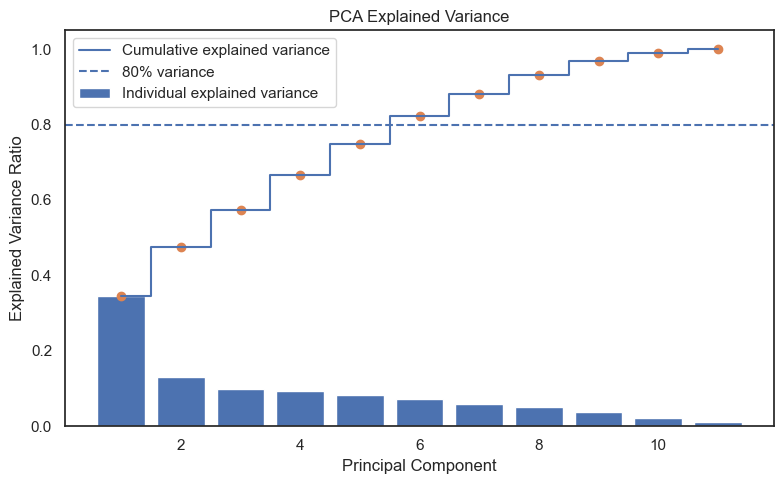

Number of components explaining at least : 80.0 %--- 6


In [78]:
components = np.arange(1, len(features) + 1)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    components,
    explained_variance,
    label="Individual explained variance"
)

ax.step(
    components,
    cumulative_variance,
    where="mid",
    label="Cumulative explained variance"
)

ax.scatter(
    components,
    cumulative_variance
)

ax.axhline(
    y=0.80,
    linestyle="--",
    label="80% variance"
)

ax.set_xlabel("Principal Component")
ax.set_ylabel("Explained Variance Ratio")
ax.set_title("PCA Explained Variance")

ax.legend()

plt.tight_layout()
plt.show()

# capturing most of the variation....choosing it as 80%
variance_val = 0.80
n_components = np.argmax(
    cumulative_variance >= variance_val
) + 1

print("Number of components explaining at least :",variance_val* 100 ,"%---",
      n_components)

In [79]:
# Interpret plot loading
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[
        f"PC{i+1}"
        for i in range(len(features))
    ]
)

loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11
GDP_PC,0.363003,0.071762,-0.106720,0.283971,0.360479,-0.125360,-0.156654,0.458038,-0.510246,-0.348516,-0.096103
GDP_Growth,0.005519,0.373044,0.590800,-0.208092,0.455218,-0.467431,-0.006663,-0.063071,0.194689,0.013156,-0.025427
Inflation,-0.078091,-0.520189,-0.180537,-0.467277,0.340712,-0.134857,0.527795,0.230386,0.016169,-0.055841,-0.055391
Unemployment,-0.033756,-0.356159,0.742192,-0.007128,-0.368953,0.139356,0.048567,0.287632,-0.283636,-0.002981,0.004044
Trade,0.251590,-0.034271,-0.013523,0.498158,-0.316444,-0.511279,0.542252,-0.095603,0.120229,0.000902,-0.089488
Capital_Formation,0.008253,0.644750,-0.037670,-0.215603,-0.219094,0.301574,0.456193,0.428557,0.042733,-0.061367,-0.003234
Life_Expectancy,0.445083,0.057319,-0.056382,-0.197573,0.015328,-0.043437,0.031211,-0.045452,-0.356373,0.783884,0.098812
Urban_Population,0.390688,-0.178089,0.007176,0.051956,-0.010418,0.072479,-0.269788,0.474449,0.674651,0.173654,-0.156004
Internet_Users,0.464230,-0.054007,0.024887,-0.228242,-0.115576,-0.007638,-0.007325,-0.143445,0.097740,-0.370444,0.740292
Electricity_Access,0.411387,0.014287,0.011818,-0.408893,-0.234740,0.028734,-0.071575,-0.338940,-0.067996,-0.299340,-0.626948


In [53]:
# SOrting by loading magnitude 
for component in ["PC1", "PC2", "PC3"]:
    
    print("\n", component)
    
    print(
        loadings[component]
        .sort_values(key=abs, ascending=False)
    )


 PC1
Internet_Users          0.464230
Life_Expectancy         0.445083
Electricity_Access      0.411387
Urban_Population        0.390688
GDP_PC                  0.363003
Trade                   0.251590
Secondary_Enrollment    0.249219
Inflation              -0.078091
Unemployment           -0.033756
Capital_Formation       0.008253
GDP_Growth              0.005519
Name: PC1, dtype: float64

 PC2
Capital_Formation       0.644750
Inflation              -0.520189
GDP_Growth              0.373044
Unemployment           -0.356159
Urban_Population       -0.178089
GDP_PC                  0.071762
Life_Expectancy         0.057319
Secondary_Enrollment   -0.056948
Internet_Users         -0.054007
Trade                  -0.034271
Electricity_Access      0.014287
Name: PC2, dtype: float64

 PC3
Unemployment            0.742192
GDP_Growth              0.590800
Secondary_Enrollment    0.224794
Inflation              -0.180537
GDP_PC                 -0.106720
Life_Expectancy        -0.056382
Capita

In [57]:
# Using PCA for clustering
X_reduced = X_pca[:, :n_components]

print("Clustering dimensions:", X_reduced.shape[1])

Clustering dimensions: 6


In [58]:
# K-Means clustering
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = np.arange(2, 9)

silhouette_scores = []
inertia_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    labels = kmeans.fit_predict(X_reduced)

    silhouette_scores.append(
        silhouette_score(X_reduced, labels)
    )

    inertia_scores.append(
        kmeans.inertia_
    )

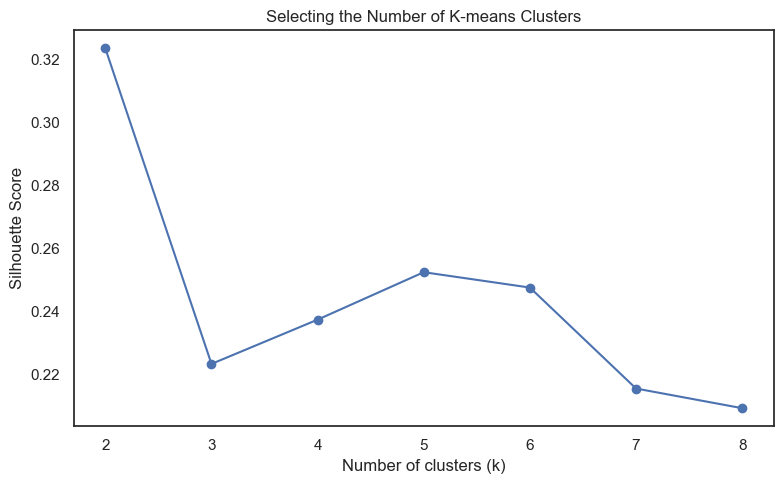

In [59]:
# Plotting both
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Selecting the Number of K-means Clusters")

plt.tight_layout()
plt.show()

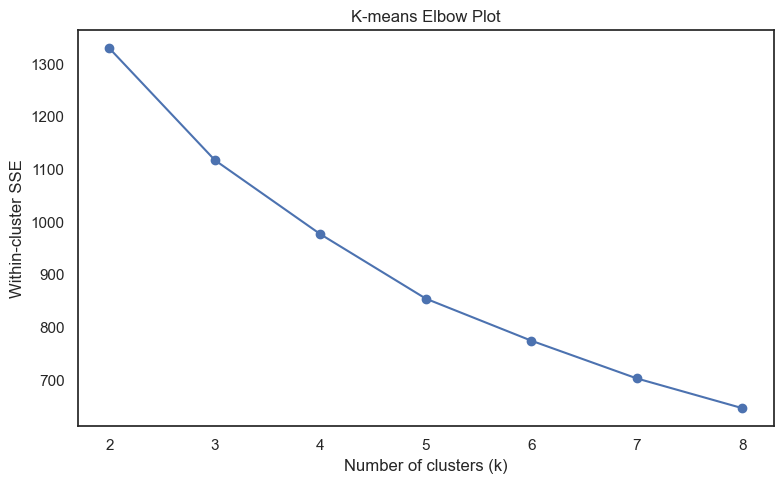

In [60]:
# Elbow
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    k_values,
    inertia_scores,
    marker="o"
)

ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Within-cluster SSE")
ax.set_title("K-means Elbow Plot")

plt.tight_layout()
plt.show()

In [61]:
best_k = k_values[
    np.argmax(silhouette_scores)
]

print("Selected k:", best_k)

Selected k: 2


In [62]:
# Final K-means
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=50
)

clusters = kmeans.fit_predict(X_reduced)

data_wide["KMeans_Cluster"] = clusters + 1

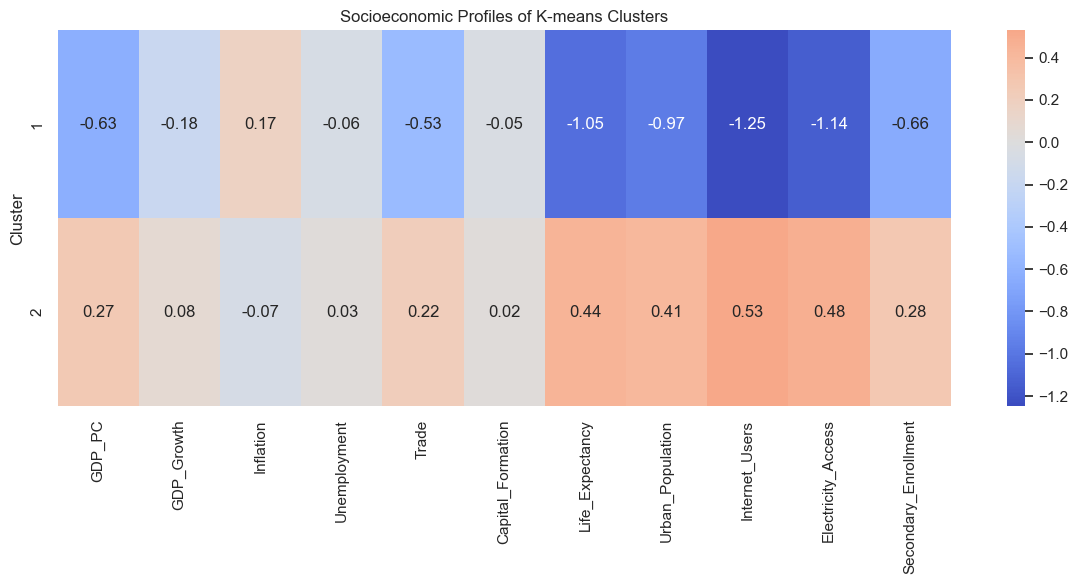

In [64]:
# describe socia economics behavior of each cluster
cluster_profiles = data_wide.groupby(
    "KMeans_Cluster"
)[features].mean()

cluster_profiles

cluster_profiles_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

cluster_profiles_scaled["Cluster"] = clusters + 1

cluster_profiles_scaled = (
    cluster_profiles_scaled
    .groupby("Cluster")
    .mean()
)

cluster_profiles_scaled

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    cluster_profiles_scaled,
    annot=True,
    fmt=".2f",
    center=0,
    cmap="coolwarm",
    ax=ax
)

ax.set_title("Socioeconomic Profiles of K-means Clusters")

plt.tight_layout()
plt.show()

In [65]:
# compare cluster with world bank  incomegroup
income_table = pd.crosstab(
    data_wide["KMeans_Cluster"],
    data_wide["IncomeGroup"]
)

income_table

IncomeGroup,High income,Low income,Lower middle income,Upper middle income
KMeans_Cluster,,,,
1,0,21,34,6
2,78,0,13,53


In [66]:
# compare clusters with grography
region_percent = pd.crosstab(
    data_wide["KMeans_Cluster"],
    data_wide["Region"],
    normalize="index"
) * 100

region_percent.round(1)

Region,East Asia & Pacific,Europe & Central Asia,Latin America & Caribbean,"Middle East, North Africa, Afghanistan & Pakistan",North America,South Asia,Sub-Saharan Africa
KMeans_Cluster,,,,,,,
1,16.4,1.6,4.9,4.9,0.0,6.6,65.6
2,17.4,37.5,24.3,13.2,2.1,1.4,4.2


In [67]:
# identify unusal countries
distances = np.linalg.norm(
    X_reduced -
    kmeans.cluster_centers_[clusters],
    axis=1
)

data_wide["Distance_to_Centroid"] = distances

unusual_countries = data_wide.sort_values(
    "Distance_to_Centroid",
    ascending=False
)

unusual_countries[
    [
        "Country Name",
        "KMeans_Cluster",
        "Distance_to_Centroid",
        "IncomeGroup",
        "Region"
    ]
].head(10)

,Country Name,KMeans_Cluster,Distance_to_Centroid,IncomeGroup,Region
110,Lebanon,2,9.013659,Lower middle income,"Middle East, North Africa, Afghanistan & Pakistan"
83,Guyana,2,8.850789,High income,Latin America & Caribbean
185,Sudan,1,7.182973,Low income,Sub-Saharan Africa
54,Djibouti,2,6.772361,Lower middle income,"Middle East, North Africa, Afghanistan & Pakistan"
116,Luxembourg,2,6.049158,High income,Europe & Central Asia
203,Ukraine,2,5.261862,Upper middle income,Europe & Central Asia
63,Eswatini,1,5.235306,Lower middle income,Sub-Saharan Africa
130,Monaco,2,5.151964,High income,Europe & Central Asia
216,Zimbabwe,1,5.124709,Lower middle income,Sub-Saharan Africa
177,South Africa,2,5.064015,Upper middle income,Sub-Saharan Africa


In [68]:
# Hierarchical clustering
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=best_k,
    linkage="ward"
)

hierarchical_clusters = hierarchical.fit_predict(
    X_reduced
)

data_wide["Hierarchical_Cluster"] = (
    hierarchical_clusters + 1
)

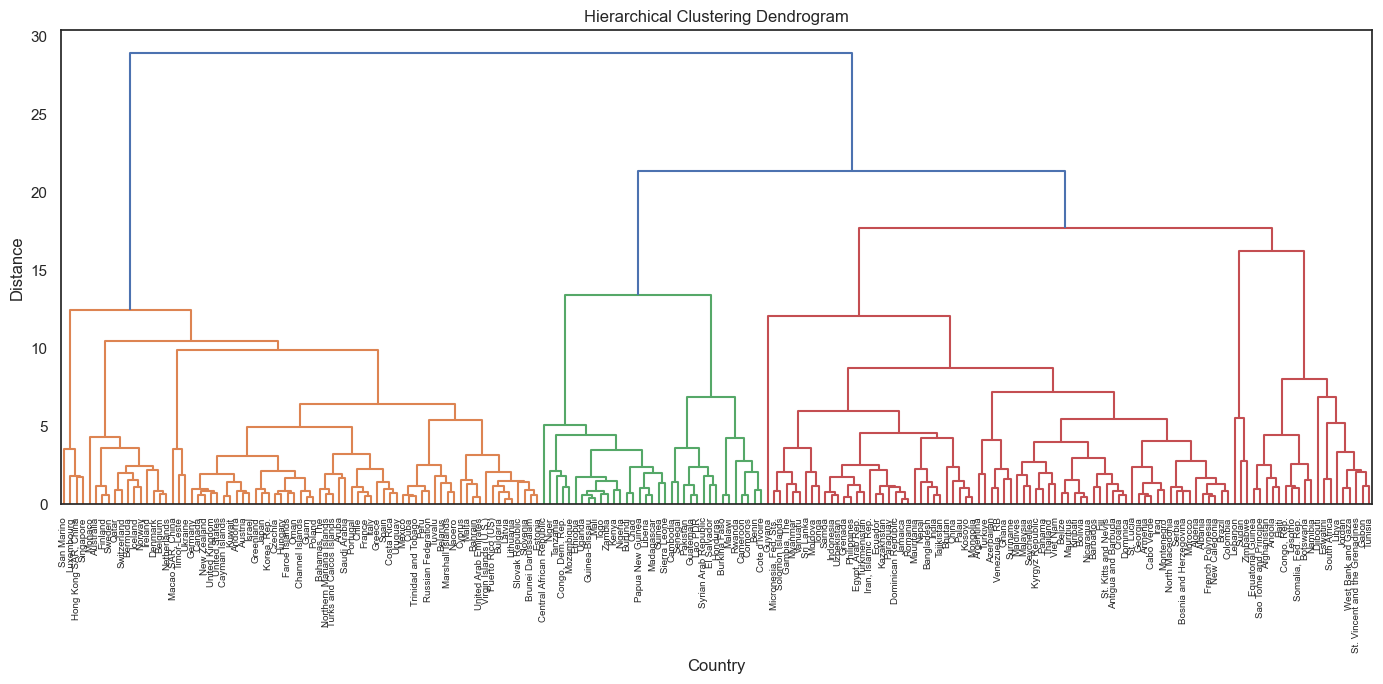

In [69]:
# Dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram

linkage_matrix = linkage(
    X_reduced,
    method="ward"
)

fig, ax = plt.subplots(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    labels=data_wide["Country Name"].tolist(),
    leaf_rotation=90,
    leaf_font_size=7,
    ax=ax
)

ax.set_title("Hierarchical Clustering Dendrogram")
ax.set_xlabel("Country")
ax.set_ylabel("Distance")

plt.tight_layout()
plt.show()

In [70]:
# Compare K-means and hierarchical clustering
comparison = pd.crosstab(
    data_wide["KMeans_Cluster"],
    data_wide["Hierarchical_Cluster"]
)

comparison

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

ari = adjusted_rand_score(
    data_wide["KMeans_Cluster"],
    data_wide["Hierarchical_Cluster"]
)

nmi = normalized_mutual_info_score(
    data_wide["KMeans_Cluster"],
    data_wide["Hierarchical_Cluster"]
)

print("Adjusted Rand Index:", ari)
print("Normalized Mutual Information:", nmi)

Adjusted Rand Index: 0.08009046974182775
Normalized Mutual Information: 0.22947297817799275
